# Grelewicz Final Project (Checkpoint 1)

This is a running notebook of my work - I wasn't sure if the checkpoint code submitted was meant to include everything I've been tinkering with, or just the final code that got to the point I wanted to be at. I will put the "final" code here, and then have another section below for my ~~struggling~~ work. That section isn't in order, since I sometimes duplicated earlier cells or whatnot.

In [ ]:
pip install brukeropusreader      ## necessary to be able to read the OPUS files with the IR data

Would you like to see the relevant wavelength and absorbance values? y or n n


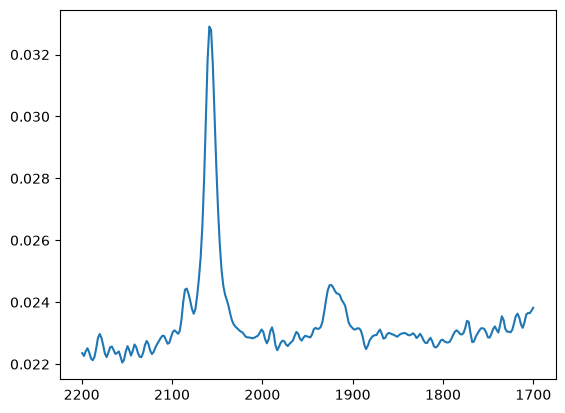

In [2]:
from brukeropusreader import read_file
import matplotlib.pyplot as plt

opus_data = read_file('./08 28 26 IR02 raw/082826_IR02.0002')

abs_spec = opus_data["AB"]
abs_spec = abs_spec[0:1867]

wave_nums = opus_data.get_range("AB")
wave_nums = wave_nums[0:1867]


wavelengths = []
absorbances = []
for (w, a) in zip(wave_nums, abs_spec):
    if w <= 2201 and w >= 1699:
        wavelengths.append(float(w))
        absorbances.append(float(a))


plt.plot(wavelengths, absorbances)
ax = plt.gca()
ax.set_xlim(ax.get_xlim()[::-1])

answer = input("Would you like to see the relevant wavelength and absorbance values? y or n")
if answer == "y":
    print()
    print(f"Wavelengths: {wavelengths}")
    print()
    print(f"Absorbances: {absorbances}")
    print()

In [ ]:
pip install pillow

In [3]:
from PIL import Image
OPUS_vers = Image.open("08 28 26 IR02 0002 spectrum from OPUS.PNG")
OPUS_vers.show()  

## I must have done something wrong with the snipping tool because I have no clue why the resolution is so low
## I just wanted to be able to compare what the processed data looks like in the OPUS program itself to the graph produced from my code

#

### Previous Tinkering

In [25]:
import brukeropusreader
from brukeropusreader import read_file

with open("./test data/090926_IR04.0002", "r") as opus_file1:
    opus_data = read_file(opus_file1)
    print(f"{opus_data["AB"]}")

TypeError: expected str, bytes or os.PathLike object, not TextIOWrapper

In [27]:
from brukeropusreader import read_file
opus_data = read_file("./test data/090926_IR04.0002")
print(f"{opus_data["AB"]}")

ImportError: cannot import name 'parse_meta' from 'brukeropusreader' (C:\Users\ashly\miniconda3\Lib\site-packages\brukeropusreader\__init__.py)

In [14]:
ls

 Volume in drive C is Windows
 Volume Serial Number is 5C90-3B09

 Directory of C:\Users\ashly\courseFolder

11/02/2026  08:46 PM    <DIR>          .
11/02/2026  08:46 PM    <DIR>          ..
09/01/2026  01:33 PM            19,285 .grelewicz_W2Tuesday.ipynb
11/01/2026  08:26 PM    <DIR>          .ipynb_checkpoints
11/02/2026  08:20 PM    <DIR>          9-09-26 04
10/22/2026  01:30 PM             2,218 elements.csv
10/22/2026  02:42 PM             1,251 fibo100.txt
10/22/2026  02:46 PM             1,274 fibo100_2.txt
08/27/2026  02:43 PM             4,759 Grelewicz.ipynb
10/08/2026  11:13 AM            19,066 grelewicz_Midterm_1_review.ipynb
10/08/2026  02:50 PM            17,428 grelewicz_Midterm1.ipynb
10/08/2026  11:33 AM             6,817 grelewicz_Midterm1_mock.ipynb
10/13/2026  01:41 PM            16,917 grelewicz_Midterm1_solutions.ipynb
09/08/2026  01:58 PM             5,537 grelewicz_PA0.ipynb
09/13/2026  01:06 PM             9,828 grelewicz_PA1.ipynb
09/27/2026  11:06 PM      

In [19]:
with open("./test data/090926_IR04.0002", "rb") as opus_file1:
    print(opus_file1.read())

b'\n\n\xfe\xfe\x00\x00\x00\x00\\\x18,A\x18\x00\x00\x00(\x00\x00\x00\x11\x00\x00\x00\x004\x00\x00x\x00\x00\x00\x18\x00\x00\x00`\x00\x00\x00<\x00\x00\x00\xf8\x01\x00\x00@\x00\x00\x00\x1e\x00\x00\x00\xe8\x02\x00\x000\x00\x00\x002\x00\x00\x00`\x03\x00\x00\x07\x04\x00\x00L\x07\x00\x00 \x05\x00\x00\x0f\x10\x00\x00L\x07\x00\x00\xc0"\x00\x00(\x00\x00\x00\x8e\x00\x00\x00`@\x00\x00h\x00\x00\x00J\x00\x00\x00\x98B\x00\x008\x00\x00\x002\x00\x00\x00\xc0C\x00\x00H\x00\x00\x00\x1e\x00\x00\x00\x88D\x00\x00\x1b\x04\x00\x00,\x00\x00\x00\x00E\x00\x00\x0b\x04\x00\x00R\x07\x00\x00\xb0E\x00\x00\x1f\x10\x00\x00,\x00\x00\x00Xo\x00\x00\x17\x04\x00\x00,\x00\x00\x00\x08p\x00\x00\xa0\x00\x00\x00J\x00\x00\x00\xb8p\x00\x00 \x00\x00\x00\x8a\x00\x00\x00\xe0q\x00\x00\x00\x00h@\xc0\n\x00\x00\x08t\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00

In [29]:
from typing import List

from brukeropusreader.block_data import BlockMeta, UnknownBlockType
from brukeropusreader.constants import (
    HEADER_LEN,
    FIRST_CURSOR_POSITION,
    META_BLOCK_SIZE,
)
from brukeropusreader.opus_data import OpusData
from brukeropusreader.opus_reader import (
    read_data_type,
    read_channel_type,
    read_text_type,
    read_chunk_size,
    read_offset,
)


def read_file(file_path: str) -> OpusData:
    with open(file_path, "rb") as opus_file:
        data = opus_file.read()
    meta_data = parse_meta(data)
    opus_data = parse_data(data, meta_data)
    return opus_data


def parse_meta(data: bytes) -> List[BlockMeta]:
    header = data[:HEADER_LEN]
    spectra_meta = []
    cursor = FIRST_CURSOR_POSITION
    while True:
        if cursor + META_BLOCK_SIZE > HEADER_LEN:
            break

        data_type = read_data_type(header, cursor)
        channel_type = read_channel_type(header, cursor)
        text_type = read_text_type(header, cursor)
        chunk_size = read_chunk_size(header, cursor)
        offset = read_offset(header, cursor)

        if offset <= 0:
            break

        block_meta = BlockMeta(data_type, channel_type,
                               text_type, chunk_size, offset)

        spectra_meta.append(block_meta)

        next_offset = offset + 4 * chunk_size
        if next_offset >= len(data):
            break
        cursor += META_BLOCK_SIZE
    return spectra_meta


def parse_data(data: bytes, blocks_meta: List[BlockMeta]) -> OpusData:
    opus_data = OpusData()
    for block_meta in blocks_meta:
        try:
            name, parser = block_meta.get_name_and_parser()
        except UnknownBlockType:
            continue
        parsed_data = parser(data, block_meta)
        opus_data[name] = parsed_data
    return opus_data


opus_data = read_file("./test data/090926_IR04.0002")
print(f"{opus_data["AB"]}")

[ 0.          0.          0.         ... -0.00052444  0.0106527
  0.        ]


In [5]:
from brukeropusreader import read_file

opus_data = read_file('./test data/090926_IR04.0003')

print(f'Parsed fields: '
      f'{list(opus_data.keys())}')

print(f'Absorption spectrum: '
      f'{opus_data["AB"]}')

Parsed fields: ['Text Information', 'Optik', 'Fourier Transformation', 'Acquisition', 'ScSm', 'AB', 'Instrument (Rf)', 'Optik (Rf)', 'Acquisition (Rf)', 'Fourier Transformation (Rf)', 'ScRf Data Parameter', 'ScRf', 'AB Data Parameter', 'ScSm Data Parameter', 'Sample', 'Instrument', 'History']
Absorption spectrum: [ 0.00000000e+00  0.00000000e+00  7.46365404e-05 ... -3.58953550e-02
 -1.58610493e-02  0.00000000e+00]


[0.00000000e+00 0.00000000e+00 7.46365404e-05 3.07449489e-04
 5.20911010e-04 5.91574935e-04 5.60622488e-04 4.66365425e-04
 3.18639679e-04 2.70342221e-04 3.64533626e-04 4.37573181e-04
 3.95489973e-04 3.92535236e-04 4.70839266e-04 3.90708912e-04
 2.11939332e-04 1.62098644e-04 2.12609506e-04 3.05001973e-04
 3.76035459e-04 3.89191933e-04 3.83115344e-04 3.54133081e-04
 3.68511421e-04 4.98050475e-04 5.49847842e-04 3.14036733e-04
 2.63986876e-05 0.00000000e+00 7.55738001e-05 7.02637772e-05
 6.14818418e-06 5.94442827e-05 2.50122597e-04 3.30819719e-04
 2.14764732e-04 1.33149064e-04 1.53386820e-04 9.18150181e-05
 0.00000000e+00 5.88202383e-05 1.72300031e-04 2.08057056e-04
 1.82657241e-04 1.17956879e-04 7.98776018e-05 7.98516703e-05
 3.38925165e-05 0.00000000e+00 7.67867605e-05 2.09639518e-04
 2.63009744e-04 2.08250931e-04 2.29623751e-04 3.96596093e-04
 5.61816036e-04 8.97226972e-04 1.55587145e-03 2.08279374e-03
 2.11649900e-03 1.82358408e-03 1.43622770e-03 1.10179721e-03
 9.40634520e-04 1.099107

<function matplotlib.pyplot.show(close=None, block=None)>

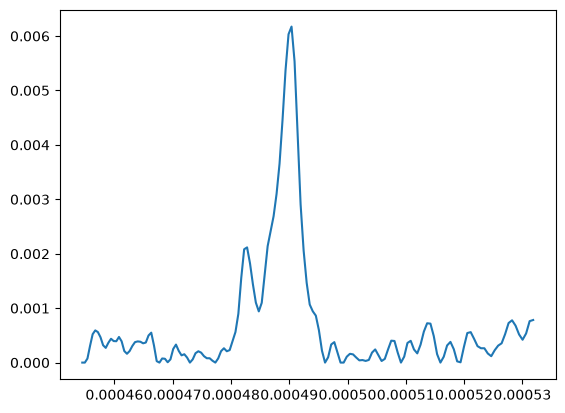

In [17]:
from brukeropusreader import read_file
import matplotlib.pyplot as plt

opus_data = read_file('./test data/090926_IR04.0003')

# print(f'Absorption spectrum: '
#       f'{opus_data["AB"]}')

# print(opus_data.get_range("AB"))

abs_spec = opus_data["AB"]
abs_spec = abs_spec[0:150]
abs_spec = abs(abs_spec)
print(abs_spec)

wave_nums = opus_data.get_range("AB")
wave_nums = wave_nums[0:1500:10]
print(wave_nums)


# abs_spec = opus_data["AB"]
# abs_spec = abs_spec[0:1500]       ## 1500 gets 18--s
# abs_spec = abs(abs_spec)
# print(abs_spec)

# wave_nums = opus_data.get_range("AB")
# wave_nums = wave_nums[0:1500]
# print(wave_nums)



# plt.plot(wave_nums, abs_spec)
# plt.show


plt.plot(1/wave_nums, abs_spec)
plt.show

In [15]:
from typing import List

from brukeropusreader.block_data import BlockMeta, UnknownBlockType
from brukeropusreader.constants import (
    HEADER_LEN,
    FIRST_CURSOR_POSITION,
    META_BLOCK_SIZE,
)
from brukeropusreader.opus_data import OpusData
from brukeropusreader.opus_reader import (
    read_data_type,
    read_channel_type,
    read_text_type,
    read_chunk_size,
    read_offset,
)


def read_file(file_path: str) -> OpusData:
    with open(file_path, "rb") as opus_file:
        data = opus_file.read()
    meta_data = parse_meta(data)
    opus_data = parse_data(data, meta_data)
    return opus_data


def parse_meta(data: bytes) -> List[BlockMeta]:
    header = data[:HEADER_LEN]
    spectra_meta = []
    cursor = FIRST_CURSOR_POSITION
    while True:
        if cursor + META_BLOCK_SIZE > HEADER_LEN:
            break

        data_type = read_data_type(header, cursor)
        channel_type = read_channel_type(header, cursor)
        text_type = read_text_type(header, cursor)
        chunk_size = read_chunk_size(header, cursor)
        offset = read_offset(header, cursor)

        if offset <= 0:
            break

        block_meta = BlockMeta(data_type, channel_type,
                               text_type, chunk_size, offset)

        spectra_meta.append(block_meta)

        next_offset = offset + 4 * chunk_size
        if next_offset >= len(data):
            break
        cursor += META_BLOCK_SIZE
    return spectra_meta


def parse_data(data: bytes, blocks_meta: List[BlockMeta]) -> OpusData:
    opus_data = OpusData()
    for block_meta in blocks_meta:
        try:
            name, parser = block_meta.get_name_and_parser()
        except UnknownBlockType:
            continue
        parsed_data = parser(data, block_meta)
        opus_data[name] = parsed_data
    return opus_data

from brukeropusreader import read_file
import matplotlib.pyplot as plt

opus_data = read_file('./test data/08 11 26 IR05 raw/081126_IR05.0004')          ## NEED THE RAW DATA!!!

# print(f'Absorption spectrum: '
#       f'{opus_data["AB"]}')

# print(opus_data.get_range("AB"))

abs_spec = opus_data["AB"]
abs_spec = abs_spec[0:1867]
abs_spec = abs(abs_spec)
print(abs_spec)

wave_nums = opus_data.get_range("AB")
wave_nums = wave_nums[0:1867]
print(wave_nums)

[0.00428869 0.00458834 0.00455692 ... 0.00106779 0.01738229 0.027683  ]
[3997.57006967 3995.64270407 3993.71533846 ...  404.96058423  403.03321863
  401.10585302]


<function matplotlib.pyplot.show(close=None, block=None)>

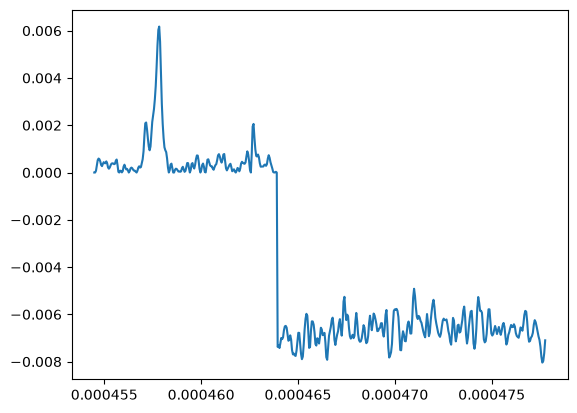

In [37]:
plt.plot(1/wave_nums, abs_spec)
plt.show

In [ ]:
from brukeropusreader import read_file
import matplotlib.pyplot as plt

opus_data = read_file('./test data/090926_IR04.0003')

abs_spec = opus_data["AB"]
abs_spec = abs_spec[0:500]

wave_nums = opus_data.get_range("AB")
wave_nums = wave_nums[0:500]

plt.plot(wave_nums, abs_spec)
plt.show

[0.00428869 0.00458834 0.00455692 ... 0.00106779 0.01738229 0.027683  ]
[3997.57006967 3995.64270407 3993.71533846 ...  404.96058423  403.03321863
  401.10585302]


(2216.684251781256, 1835.0658622335225)

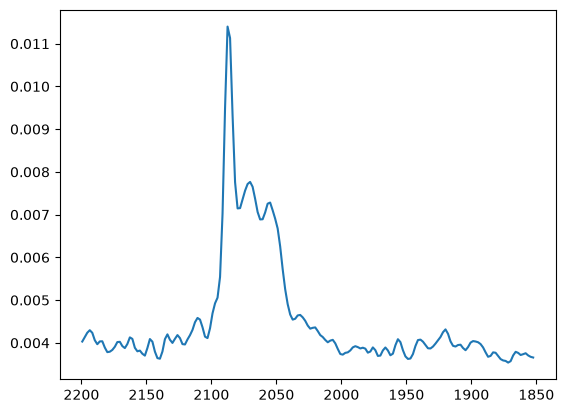

In [81]:
from brukeropusreader import read_file
import matplotlib.pyplot as plt

opus_data = read_file('./test data/08 11 26 IR05 raw/081126_IR05.0004')

abs_spec = opus_data["AB"]
abs_spec = abs_spec[0:1867]
abs_spec = abs(abs_spec)
print(abs_spec)

wave_nums = opus_data.get_range("AB")
wave_nums = wave_nums[0:1867]
print(wave_nums)

# abs_spec_cut = list()
# for abs_point in abs_spec:
#     if abs_point <= 2200 and abs_point >= 1850:
#         abs_spec_cut.append(abs_point)
#     else:
#         continue
# print(abs_spec_cut)

wave_nums_cut = []
for wave_point in wave_nums:
    if wave_point <= 2201 and wave_point >= 1851:
        wave_nums_cut.append(float(wave_point))
    else:
        wave_nums_cut.append(0)
# print(wave_nums_cut)

# for count in abs_spec:
#     if wave_nums_cut[count] != 0:
#         plt.plot(wave_nums_cut[count], float(abs_spec[count]))      ## wrong format

# for absorbance in abs_spec:                                  ## takes waaaay too much processing
#     for wavelength in wave_nums_cut:
#         if wavelength != 0:
#             plt.plot(wavelength, absorbance)
# plt.show()


# while wavelength in wave_nums_cut != 0:          ## doesn't continue to next number
#     print(wavelength)
#     continue

# def validation(wavelength, absorbance):
#     if wavelength != 0:
#         print(wavelength, absorbance)

wavelengths = []
absorbances = []
for (w, a) in zip(wave_nums_cut, abs_spec):
    if w != 0:
        wavelengths.append(float(w))
        absorbances.append(float(a))
# print(wavelengths, absorbances)
plt.plot(wavelengths, absorbances)
ax = plt.gca()
ax.set_xlim(ax.get_xlim()[::-1])

# count = 0
# while count >= 1867 and wave_nums_cut[count] == 0:
#     print(wave_nums_cut[count], abs_nums[count])                 ## prints Nothing
#     count += 1



# plt.plot(wave_nums, abs_spec)
# ax = plt.gca()
# ax.set_xlim(ax.get_xlim()[::-1])



# ax.set_xlim(2200,1790)
# ax.autoscale_view()